<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week5/lesson18/Lesson18_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 18 — Binomial, Poisson, Gaussian: Models, Likelihood and Fit

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 5 — Probability\
**Lesson:** Lesson 18\
**Notebook type:** Teaching notebook

> *"All models are wrong; the question is whether this one is wrong in a way that matters."* (after George Box)

---

### From describing variability to modelling it

Lesson 17 described distributions with their PMF, CDF, mean and variance, and used the Poisson process as a reference without deriving it. This lesson introduces the three distributions that do most of the work in neural data analysis, each built from a simple mechanism:

- **binomial**: the number of successes in a fixed number of independent yes/no trials (correct choices, vesicles released);
- **Poisson**: the number of events in an interval when events are rare and independent (spikes, photon absorptions, miniature synaptic events);
- **Gaussian**: what sums and averages of many independent contributions look like (the central limit theorem).

We will also meet the three steps of using a model on data:
1. **estimate** its parameters from data, by **maximum likelihood**;
2. **quantify** how precise the estimate is;
3. **check** whether the model fits, by comparing the data with simulations from the fitted model.

The mini-lab fits a binomial model to a mouse's choices ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x)) and tests the Poisson model on spike counts from the same experiment's motor cortex, where it fails in an instructive way.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from math import comb, factorial
from scipy import stats

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-17.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-17.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: Could a Guessing Mouse Do That?**

A mouse chooses correctly on 9 of 10 difficult trials. If it were guessing (each trial correct with probability $\tfrac12$, independently of the others), how likely is a score at least that good?

- Each specific sequence of 10 outcomes has probability $(\tfrac12)^{10} = 1/1024$.
- Exactly 10 correct: 1 sequence. Exactly 9 correct: $\binom{10}{9} = 10$ sequences (which trial was wrong).
- $P(\text{9 or more correct}) = (1 + 10)/1024 \approx 0.011$.

**Prediction before running:** is 9 of 10 convincing evidence that the mouse is not guessing? What about 42 of 49, the score of the mini-lab mouse on its hardest trials?

About 1% of guessing mice would score 9 of 10, so it is suggestive; 42 of 49 by guessing has probability below one in a million. Counting sequences and multiplying probabilities of independent trials is exactly the **binomial distribution**, the first model of this lesson.

In [3]:
p_tail = sum(comb(10, k) for k in [9, 10]) / 2**10
print(f"P(at least 9 of 10 correct | guessing) = 11/1024 = {p_tail:.4f}")
print(f"P(at least 42 of 49 correct | guessing) = {sum(comb(49, k) for k in range(42, 50)) / 2**49:.2e}")

P(at least 9 of 10 correct | guessing) = 11/1024 = 0.0107
P(at least 42 of 49 correct | guessing) = 1.81e-07


# **Part 1: Bernoulli Trials and the Binomial Distribution**

A **Bernoulli** variable $B$ takes the value 1 ("success") with probability $p$ and 0 otherwise:

$$E[B] = p,\qquad \operatorname{Var}(B) = E[B^2] - p^2 = p - p^2 = p(1 - p).$$

The number of successes $K = B_1 + \dots + B_n$ in $n$ **independent** Bernoulli trials with the **same** $p$ has the **binomial distribution**, $K \sim \operatorname{Binomial}(n, p)$:

$$P(K = k) = \binom{n}{k}p^k(1 - p)^{n - k},\qquad k = 0, 1, \dots, n,\qquad \binom{n}{k} = \frac{n!}{k!\,(n - k)!}.$$

Each particular sequence with $k$ successes has probability $p^k(1 - p)^{n - k}$, and $\binom{n}{k}$ counts the sequences. By linearity and the variance-of-a-sum rule (Lesson 17, independent terms):

$$E[K] = np,\qquad \operatorname{Var}(K) = np(1 - p),\qquad \text{Fano factor} = 1 - p < 1.$$

**Assumptions that matter:** a fixed number of trials $n$; independence; the same $p$ on every trial. If $p$ varies from trial to trial (a mouse whose attention drifts, release sites with different probabilities), the counts are **more variable** than binomial.

**Example: quantal release.** A synapse has $n = 10$ release sites, each releasing a vesicle with probability $p = 0.3$ per action potential, independently (the quantal model of del Castillo and Katz).

PMF from the formula matches scipy.stats.binom: True
mean 3.000 (np = 3.0),  variance 2.100 (np(1-p) = 2.10)
P(no release) = 0.7^10 = 0.0282;  P(at least 5 vesicles) = 0.1503


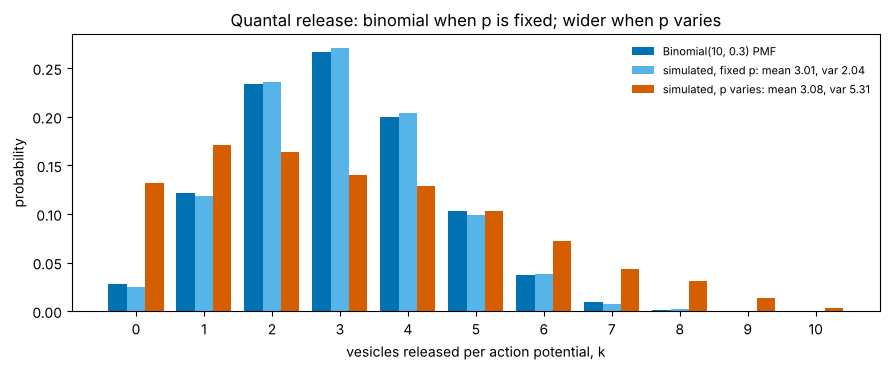

In [4]:
def binom_pmf(k, n, p):
    # Binomial PMF from the formula; k may be an array of integers in 0..n.
    k = np.asarray(k)
    return np.array([comb(n, int(kk)) * p**kk * (1 - p)**(n - kk) for kk in k.ravel()]).reshape(k.shape)

n_sites, p_rel = 10, 0.3
k_b = np.arange(n_sites + 1)
pmf_b = binom_pmf(k_b, n_sites, p_rel)                                    # (11,)
print("PMF from the formula matches scipy.stats.binom:", np.allclose(pmf_b, stats.binom.pmf(k_b, n_sites, p_rel)))
print(f"mean {np.sum(k_b * pmf_b):.3f} (np = {n_sites * p_rel}),  variance {np.sum((k_b - 3)**2 * pmf_b):.3f} (np(1-p) = {n_sites * p_rel * (1 - p_rel):.2f})")
print(f"P(no release) = 0.7^10 = {pmf_b[0]:.4f};  P(at least 5 vesicles) = {pmf_b[5:].sum():.4f}")

sites = RNG.random((2000, n_sites)) < p_rel                                # (2000, 10): action potentials x release sites
released = sites.sum(axis=1)                                               # (2000,) vesicles per action potential
p_var = np.clip(RNG.beta(1.5, 3.5, size=(2000, 1)), 0, 1)                  # (2000, 1) p drifting between action potentials, mean 0.3
released_var = (RNG.random((2000, n_sites)) < p_var).sum(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(k_b - 0.27, pmf_b, width=0.27, color=PALETTE[0], label='Binomial(10, 0.3) PMF')
ax.bar(k_b, np.bincount(released, minlength=11) / 2000, width=0.27, color=PALETTE[5], label=f'simulated, fixed p: mean {released.mean():.2f}, var {released.var(ddof=1):.2f}')
ax.bar(k_b + 0.27, np.bincount(released_var, minlength=11) / 2000, width=0.27, color=PALETTE[1], label=f'simulated, p varies: mean {released_var.mean():.2f}, var {released_var.var(ddof=1):.2f}')
ax.set_xlabel('vesicles released per action potential, k'); ax.set_ylabel('probability'); ax.set_xticks(k_b)
ax.set_title('Quantal release: binomial when p is fixed; wider when p varies')
ax.legend(fontsize=8, frameon=False); plt.tight_layout(); plt.show()

With a fixed release probability, the simulated counts match the binomial PMF (mean 3, variance 2.1). When $p$ drifts between action potentials with the **same average** 0.3, the mean is unchanged but the variance is far larger: the law of total variance of Lesson 17, $\operatorname{Var}(K) = E[\operatorname{Var}(K \mid p)] + \operatorname{Var}(E[K \mid p])$. A variance larger than $np(1 - p)$ is a sign that the binomial's "same $p$" assumption fails.

# **Part 2: The Poisson Distribution**

### From binomial to Poisson
Split a window of length $w$ into $n$ tiny bins of width $w/n$. Suppose a neuron fires at constant rate $r$ (spikes/s), at most one spike per tiny bin, independently across bins, each with probability $rw/n$. The spike count is $\operatorname{Binomial}(n, \lambda/n)$ with $\lambda = rw$. As $n \to \infty$,

$$\binom{n}{k}\Big(\frac{\lambda}{n}\Big)^k\Big(1 - \frac{\lambda}{n}\Big)^{n - k} = \frac{n(n-1)\cdots(n-k+1)}{n^k}\cdot\frac{\lambda^k}{k!}\cdot\Big(1 - \frac{\lambda}{n}\Big)^{n}\Big(1 - \frac{\lambda}{n}\Big)^{-k} \;\longrightarrow\; 1\cdot\frac{\lambda^k}{k!}\cdot e^{-\lambda}\cdot 1 .$$

This is the **Poisson distribution**, $N \sim \operatorname{Poisson}(\lambda)$:

$$P(N = k) = \frac{\lambda^k e^{-\lambda}}{k!},\qquad k = 0, 1, 2, \dots,\qquad E[N] = \operatorname{Var}(N) = \lambda .$$

### Properties used throughout neuroscience
- **Rate × interval:** $\lambda = r\,w$. Counts in a window twice as long have twice the mean, **and twice the variance**; the Fano factor is 1 for every window (**interval scaling**).
- **Mean = variance.** This is the property the Fano factor tests. It holds for a Poisson model, not for neurons in general.
- **Sums:** independent Poisson counts add to a Poisson count, $\operatorname{Poisson}(\lambda_1) + \operatorname{Poisson}(\lambda_2) = \operatorname{Poisson}(\lambda_1 + \lambda_2)$.
- **Intervals:** the waiting time between events of a Poisson process is **exponential** with mean $1/r$, so $P(T > t) = P(\text{no spike in } t) = e^{-rt}$ and CV = 1 (Lesson 17).
- **Assumptions:** constant rate; independence (no refractory period, no bursting, no history dependence). Real neurons violate both: refractoriness pushes the Fano factor below 1 at short windows; rate fluctuations push it above 1 at long windows.

In [5]:
def poisson_pmf(k, lam):
    k = np.asarray(k)
    return np.array([lam**int(kk) * np.exp(-lam) / factorial(int(kk)) for kk in k.ravel()]).reshape(k.shape)

lam = 4.0
k_p = np.arange(0, 21)
print("Poisson PMF from the formula matches scipy.stats.poisson:", np.allclose(poisson_pmf(k_p, lam), stats.poisson.pmf(k_p, lam)))
print(f"{'n bins':>8}{'p = lambda/n':>14}{'total variation distance to Poisson(4)':>40}")
for n in [5, 10, 20, 50, 200, 1000]:
    tv = 0.5 * np.sum(np.abs(stats.binom.pmf(k_p, n, lam / n) - stats.poisson.pmf(k_p, lam))) + 0.5 * stats.poisson.sf(20, lam)
    print(f"{n:>8}{lam / n:>14.4f}{tv:>40.4f}")

# A Poisson process at 20 spikes/s: counts in windows of different lengths, and intervals.
rate = 20.0
spike_times = np.cumsum(RNG.exponential(1 / rate, 30000)); spike_times = spike_times[spike_times < 1000]   # (n_spikes,) s
print(f"\n{'window':>8}{'lambda = r w':>13}{'mean count':>12}{'variance':>10}{'Fano':>7}")
for w in [0.01, 0.05, 0.2, 1.0, 5.0]:
    cnt = np.histogram(spike_times, bins=np.arange(0, 1000 + 1e-9, w))[0]
    print(f"{w * 1000:>6.0f}ms{rate * w:>13.2f}{cnt.mean():>12.3f}{cnt.var(ddof=1):>10.3f}{cnt.var(ddof=1) / cnt.mean():>7.3f}")
isi = np.diff(spike_times)
print(f"intervals: mean {isi.mean() * 1000:.1f} ms (1/r = 50), CV {isi.std(ddof=1) / isi.mean():.3f};  P(T > 100 ms) = {np.mean(isi > 0.1):.3f} (e^(-2) = {np.exp(-2):.3f})")

Poisson PMF from the formula matches scipy.stats.poisson: True
  n bins  p = lambda/n  total variation distance to Poisson(4)
       5        0.8000                                  0.3951
      10        0.4000                                  0.1267
      20        0.2000                                  0.0560
      50        0.0800                                  0.0209
     200        0.0200                                  0.0051
    1000        0.0040                                  0.0010

  window lambda = r w  mean count  variance   Fano
    10ms         0.20       0.200     0.200  0.999
    50ms         1.00       0.999     0.999  1.000
   200ms         4.00       3.996     4.066  1.018
  1000ms        20.00      19.978    19.885  0.995
  5000ms       100.00      99.890   110.038  1.102
intervals: mean 50.0 ms (1/r = 50), CV 1.002;  P(T > 100 ms) = 0.133 (e^(-2) = 0.135)


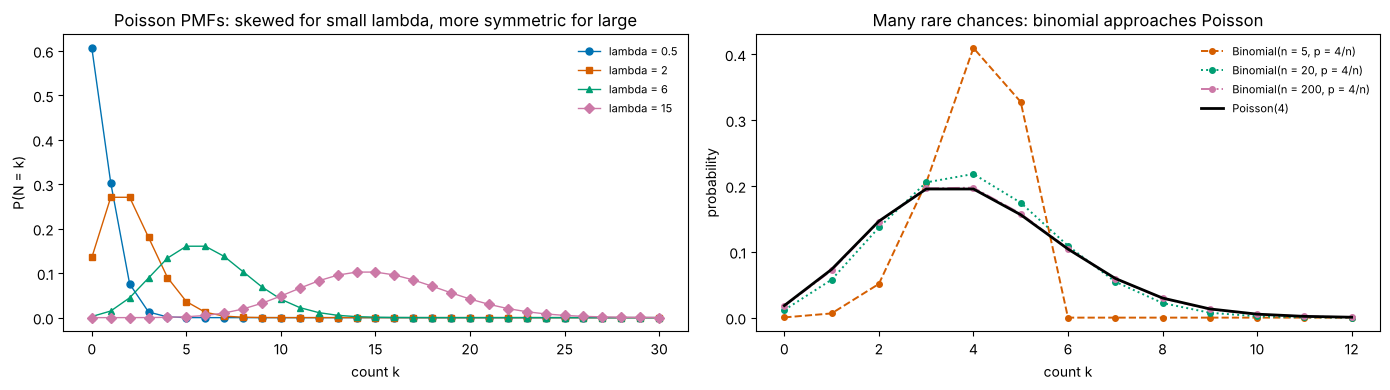

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for lam_i, c, mk in zip([0.5, 2, 6, 15], PALETTE, MARKERS):
    kk = np.arange(0, 31)
    axes[0].plot(kk, stats.poisson.pmf(kk, lam_i), marker=mk, color=c, lw=1, ms=5, label=f'lambda = {lam_i}')
axes[0].set_xlabel('count k'); axes[0].set_ylabel('P(N = k)'); axes[0].set_title('Poisson PMFs: skewed for small lambda, more symmetric for large')
axes[0].legend(fontsize=8, frameon=False)
for n, c, ls in zip([5, 20, 200], PALETTE[1:], LINESTYLES[1:]):
    axes[1].plot(k_p[:13], stats.binom.pmf(k_p[:13], n, lam / n), ls, color=c, marker='o', ms=4, lw=1.4, label=f'Binomial(n = {n}, p = 4/n)')
axes[1].plot(k_p[:13], stats.poisson.pmf(k_p[:13], lam), 'k-', lw=2, label='Poisson(4)')
axes[1].set_xlabel('count k'); axes[1].set_ylabel('probability'); axes[1].set_title('Many rare chances: binomial approaches Poisson')
axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

With 5 bins the binomial is still noticeably narrower than the Poisson (its variance is $np(1-p) = 4 \times 0.2 = 0.8\lambda$); with 200 bins the two are almost indistinguishable. The simulated Poisson process confirms the scaling: the mean count is exactly proportional to the window, and so is the variance, so the Fano factor stays at 1 from 10 ms to 5 s. The motor-cortex neurons of the mini-lab will not behave like this.

#### Interactive version: from binomial to Poisson

In [7]:
n_list = [2, 3, 5, 8, 12, 20, 40, 100, 400]
kk = np.arange(0, 15)
fig_b = go.Figure([go.Bar(x=kk, y=np.round(stats.binom.pmf(kk, n_list[0], 4 / n_list[0]), 5), marker_color=PALETTE[5], name='Binomial(n, 4/n)'),
                   go.Scatter(x=kk, y=np.round(stats.poisson.pmf(kk, 4), 5), mode='lines+markers', line=dict(color='black'), name='Poisson(4)')])
fr = []
for i, n in enumerate(n_list):
    pb = stats.binom.pmf(kk, n, 4 / n)
    tv = 0.5 * np.sum(np.abs(stats.binom.pmf(np.arange(0, 60), n, 4 / n) - stats.poisson.pmf(np.arange(0, 60), 4)))
    fr.append(go.Frame(name=str(i), traces=[0], data=[go.Bar(y=np.round(pb, 5))],
                       layout=go.Layout(title=f'n = {n} bins, p = {4 / n:.3f} per bin: variance {n * (4 / n) * (1 - 4 / n):.2f} (Poisson 4);  total variation distance {tv:.3f}')))
fig_b.frames = fr
buttons, sliders = play_pause_and_slider(n_list, prefix='n = ', duration=600)
fig_b.update_layout(title=fr[0].layout.title.text, xaxis=dict(title='count k'), yaxis=dict(title='probability', range=[0, 0.55]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_b.show(config=PLOTLY_CONFIG)

# **Part 3: The Gaussian Distribution and the Central Limit Theorem**

The **Gaussian** (normal) distribution $X \sim \mathcal{N}(\mu, \sigma^2)$ has density

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\Big(-\frac{(x - \mu)^2}{2\sigma^2}\Big),\qquad E[X] = \mu,\qquad \operatorname{Var}(X) = \sigma^2 .$$

- $\mu$ is a **location** parameter (shifts the curve) and $\sigma$ a **scale** parameter (stretches it), in the units of $x$.
- **Standardisation:** $Z = (X - \mu)/\sigma \sim \mathcal{N}(0, 1)$, so every Gaussian probability is a standard-normal probability: $P(X \le x) = \Phi\big((x - \mu)/\sigma\big)$, where $\Phi$ is the standard normal CDF (`scipy.stats.norm.cdf`). There is no elementary formula for $\Phi$; it is computed numerically.
- About 68%, 95% and 99.7% of the probability lies within 1, 2 and 3 SDs of the mean (more precisely, $\pm1.96\sigma$ holds 95%).
- Linear combinations of independent Gaussians are Gaussian.

### The central limit theorem (CLT)
If $X_1, \dots, X_n$ are independent with the same distribution, mean $\mu$ and finite variance $\sigma^2$, then for large $n$ the sum is approximately Gaussian:

$$\sum_{i=1}^{n} X_i \approx \mathcal{N}(n\mu,\ n\sigma^2),\qquad \text{equivalently}\qquad \frac{\bar X - \mu}{\sigma/\sqrt n} \approx \mathcal{N}(0, 1),$$

whatever the shape of the distribution of each $X_i$. This is why Gaussians appear wherever many small independent contributions add up: membrane potentials summing many synaptic inputs, averages over trials, estimation errors. It also explains why Poisson($\lambda$) and Binomial($n, p$) look Gaussian when $\lambda$ or $np(1-p)$ is large: each is a sum of many independent pieces.

**How large is "large"?** It depends on how skewed the pieces are. For sums of independent terms the skewness shrinks like $1/\sqrt n$. **The CLT needs independence** (or weak dependence): a sum of strongly correlated terms need not become Gaussian.

P(|Z| <= 1) = 0.6827,  P(|Z| <= 1.96) = 0.9500,  P(|Z| <= 3) = 0.9973
V ~ N(-65 mV, (4 mV)^2):  P(V > -55 mV) = P(Z > 2.5) = 0.0062;  95% of values in [-72.8, -57.2] mV


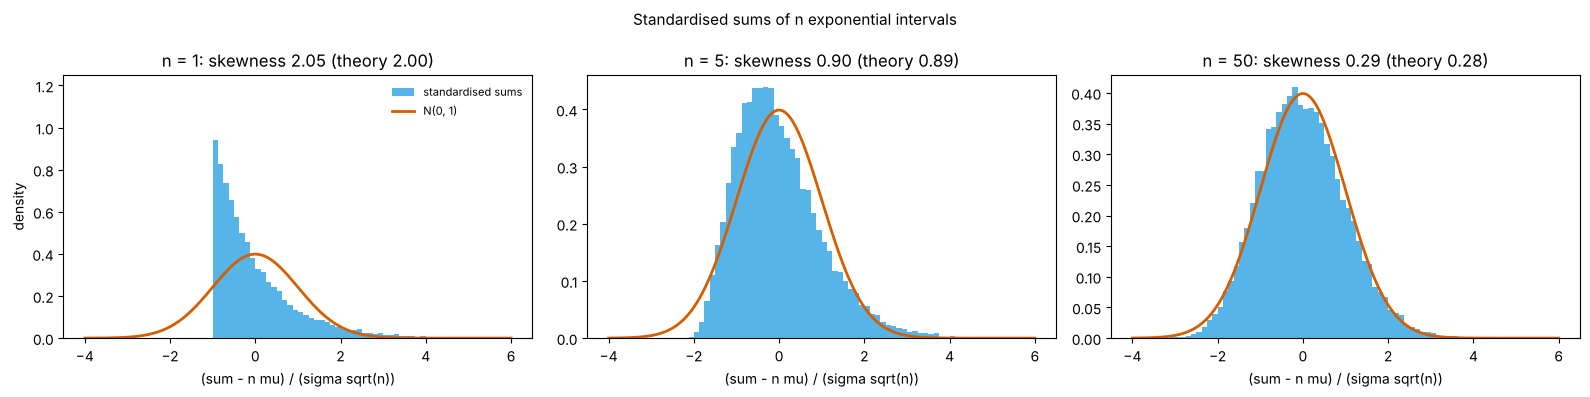

In [8]:
z = stats.norm
print(f"P(|Z| <= 1) = {z.cdf(1) - z.cdf(-1):.4f},  P(|Z| <= 1.96) = {z.cdf(1.96) - z.cdf(-1.96):.4f},  P(|Z| <= 3) = {z.cdf(3) - z.cdf(-3):.4f}")
mu_v, sd_v = -65.0, 4.0                                                      # membrane potential, mV
print(f"V ~ N(-65 mV, (4 mV)^2):  P(V > -55 mV) = P(Z > {(-55 - mu_v) / sd_v:.1f}) = {z.sf((-55 - mu_v) / sd_v):.4f};  "
      f"95% of values in [{mu_v - 1.96 * sd_v:.1f}, {mu_v + 1.96 * sd_v:.1f}] mV")

# CLT: sums of n exponential intervals (mean 50 ms, skewness 2).
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, n in zip(axes, [1, 5, 50]):
    sums = RNG.exponential(50.0, size=(20000, n)).sum(axis=1)               # (20000,) ms
    zs = (sums - n * 50) / (50 * np.sqrt(n))                                 # standardised with the exact mean and SD
    ax.hist(zs, bins=np.linspace(-4, 6, 81), density=True, color=PALETTE[5], label='standardised sums')
    xx = np.linspace(-4, 6, 300); ax.plot(xx, z.pdf(xx), color=PALETTE[1], lw=2, label='N(0, 1)')
    ax.set_title(f'n = {n}: skewness {stats.skew(sums):.2f} (theory {2 / np.sqrt(n):.2f})')
    ax.set_xlabel('(sum - n mu) / (sigma sqrt(n))')
axes[0].set_ylabel('density'); axes[0].set_ylim(0, 1.25); axes[0].legend(fontsize=8, frameon=False, loc='upper right')
fig.suptitle('Standardised sums of n exponential intervals', fontsize=11)
plt.tight_layout(); plt.show()

A single exponential interval is far from Gaussian (skewness 2). The sum of 5 is still skewed (0.90); the sum of 50 is close to the standard normal curve (skewness 0.29), in agreement with $2/\sqrt n$ (0.89 and 0.28).

#### Interactive version: the central limit theorem
The slider changes the number of independent Bernoulli(0.1) terms in a sum, i.e. a Binomial($n$, 0.1) count, standardised with its exact mean and SD.

In [9]:
ns = [1, 2, 5, 10, 20, 50, 100, 300, 1000]
xx = np.linspace(-4, 4, 200)
def clt_frame(n):
    k = np.arange(0, n + 1)
    mu_, sd_ = n * 0.1, np.sqrt(n * 0.1 * 0.9)
    return (k - mu_) / sd_, stats.binom.pmf(k, n, 0.1) * sd_            # standardised positions, density-scaled heights
x0, y0 = clt_frame(ns[0])
fig_c = go.Figure([go.Bar(x=np.round(x0, 4), y=np.round(y0, 5), marker_color=PALETTE[5], name='standardised Binomial(n, 0.1)', width=0.08),
                   go.Scatter(x=xx, y=np.round(stats.norm.pdf(xx), 5), mode='lines', line=dict(color=PALETTE[1], width=3), name='N(0, 1)')])
fr = []
for i, n in enumerate(ns):
    xs_, ys_ = clt_frame(n)
    keep = np.abs(xs_) <= 4.5
    fr.append(go.Frame(name=str(i), traces=[0], data=[go.Bar(x=np.round(xs_[keep], 4), y=np.round(ys_[keep], 5), width=min(0.9 / np.sqrt(n * 0.09), 0.9))],
                       layout=go.Layout(title=f'n = {n}: skewness {(1 - 2 * 0.1) / np.sqrt(n * 0.1 * 0.9):.2f}')))
fig_c.frames = fr
buttons, sliders = play_pause_and_slider(ns, prefix='n = ', duration=600)
fig_c.update_layout(title=fr[0].layout.title.text, xaxis=dict(title='(K - np) / sqrt(np(1-p))', range=[-4, 4]), yaxis=dict(title='density', range=[0, 1.2]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_c.show(config=PLOTLY_CONFIG)

# **Part 4: Likelihood and Parameter Estimation**

A model gives the probability of the data for each value of its parameter $\theta$. Read the other way, as a function of $\theta$ with the data fixed, this is the **likelihood**:

$$L(\theta) = P(\text{data} \mid \theta),\qquad \ell(\theta) = \log L(\theta).$$

For independent observations the likelihood is a product, so the **log-likelihood is a sum**: $\ell(\theta) = \sum_i \log P(x_i \mid \theta)$ (sums are numerically safe; products of many small numbers underflow). The **maximum-likelihood estimate** (MLE) $\hat\theta$ is the value that makes the observed data most probable. The likelihood is **not** a probability distribution over $\theta$ (it need not integrate to 1); turning it into one needs a prior, which is Lesson 19's Bayes' rule.

### Three MLEs by calculus (Lesson 11: set the derivative to zero)
- **Binomial**, $k$ successes in $n$ trials: $\ell(p) = k\log p + (n - k)\log(1 - p) + \text{const}$; $\ell'(p) = k/p - (n - k)/(1 - p) = 0 \Rightarrow \hat p = k/n$.
- **Poisson**, counts $x_1, \dots, x_m$: $\ell(\lambda) = \sum_i (x_i\log\lambda - \lambda) + \text{const}$; $\ell'(\lambda) = \sum_i x_i/\lambda - m = 0 \Rightarrow \hat\lambda = \bar x$.
- **Gaussian**: $\hat\mu = \bar x$ and $\hat\sigma^2 = \frac1m\sum_i(x_i - \bar x)^2$ (divisor $m$: the MLE of the variance is slightly biased, Lesson 17).

### Curvature measures precision
A sharply peaked log-likelihood pins the parameter down; a flat one does not. Near the maximum, $\ell(\theta) \approx \ell(\hat\theta) + \tfrac12\ell''(\hat\theta)(\theta - \hat\theta)^2$ (Lesson 11's Taylor expansion), and the standard error of the MLE is approximately

$$\operatorname{SE}(\hat\theta) \approx \frac{1}{\sqrt{-\ell''(\hat\theta)}} .$$

For the binomial, $-\ell''(\hat p) = n/\big(\hat p(1 - \hat p)\big)$, so $\operatorname{SE}(\hat p) = \sqrt{\hat p(1 - \hat p)/n}$; for the Poisson, $\operatorname{SE}(\hat\lambda) = \sqrt{\hat\lambda/m}$. Both shrink like $1/\sqrt{\text{data}}$, as in Lesson 17.

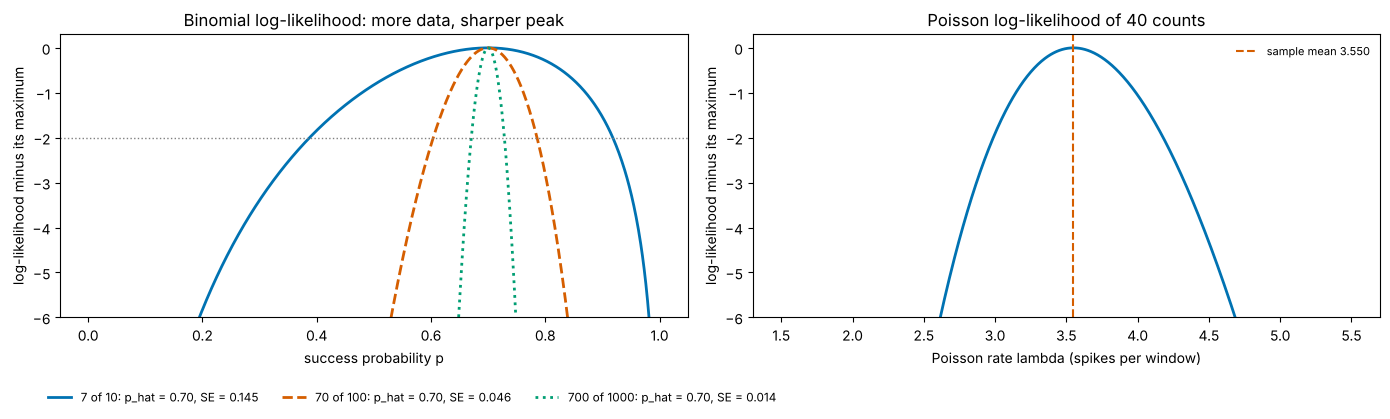

Poisson: grid maximum 3.550, sample mean 3.550;  curvature SE 0.2979, formula sqrt(lambda_hat/m) = 0.2979
binomial, 100 trials, p = 0.7: SD of p_hat across experiments 0.0459  vs  sqrt(p(1-p)/n) = 0.0458
Poisson, 40 trials, lambda = 3.2: SD of lambda_hat 0.2820  vs  sqrt(lambda/m) = 0.2828


In [10]:
p_grid = np.linspace(0.001, 0.999, 999)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (k, n), c, ls in zip([(7, 10), (70, 100), (700, 1000)], PALETTE, LINESTYLES):
    ll = k * np.log(p_grid) + (n - k) * np.log(1 - p_grid)
    ll -= ll.max()                                                          # relative log-likelihood; maximum at 0
    p_hat = p_grid[np.argmax(ll)]
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    axes[0].plot(p_grid, ll, ls, color=c, lw=2, label=f'{k} of {n}: p_hat = {p_hat:.2f}, SE = {se:.3f}')
axes[0].set_ylim(-6, 0.3); axes[0].axhline(-2, color='grey', ls=':', lw=1)
axes[0].set_xlabel('success probability p'); axes[0].set_ylabel('log-likelihood minus its maximum')
axes[0].set_title('Binomial log-likelihood: more data, sharper peak')

counts_obs = RNG.poisson(3.2, size=40)                                     # (40,) spike counts in 40 trials
lam_grid = np.linspace(1.5, 5.5, 801)
ll_p = counts_obs.sum() * np.log(lam_grid) - counts_obs.size * lam_grid
lam_num = lam_grid[np.argmax(ll_p)]
h = lam_grid[1] - lam_grid[0]; i0 = np.argmax(ll_p)
curv = (ll_p[i0 + 1] - 2 * ll_p[i0] + ll_p[i0 - 1]) / h**2                  # second difference (Lesson 9)
axes[1].plot(lam_grid, ll_p - ll_p.max(), color=PALETTE[0], lw=2)
axes[1].axvline(counts_obs.mean(), color=PALETTE[1], ls='--', label=f'sample mean {counts_obs.mean():.3f}')
axes[1].set_ylim(-6, 0.3); axes[1].set_xlabel('Poisson rate lambda (spikes per window)'); axes[1].set_ylabel('log-likelihood minus its maximum')
axes[1].set_title('Poisson log-likelihood of 40 counts'); axes[1].legend(fontsize=8, frameon=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower left', bbox_to_anchor=(0.03, 0), ncol=3, fontsize=8.5, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.show()
print(f"Poisson: grid maximum {lam_num:.3f}, sample mean {counts_obs.mean():.3f};  curvature SE {1 / np.sqrt(-curv):.4f}, formula sqrt(lambda_hat/m) = {np.sqrt(counts_obs.mean() / 40):.4f}")

# Do the standard errors describe the real spread of the estimates? Repeat the experiment many times.
p_hats = RNG.binomial(100, 0.7, size=20000) / 100
lam_hats = RNG.poisson(3.2, size=(20000, 40)).mean(axis=1)
print(f"binomial, 100 trials, p = 0.7: SD of p_hat across experiments {p_hats.std():.4f}  vs  sqrt(p(1-p)/n) = {np.sqrt(0.21 / 100):.4f}")
print(f"Poisson, 40 trials, lambda = 3.2: SD of lambda_hat {lam_hats.std():.4f}  vs  sqrt(lambda/m) = {np.sqrt(3.2 / 40):.4f}")

The three binomial curves all peak at $\hat p = 0.7$, but with 1,000 trials the peak is ten times narrower than with 10: 100 times the data, and $\sqrt{100} = 10$. The dotted line at $-2$ marks, roughly, the range of parameter values "compatible" with the data (about $\hat\theta \pm 2\,\mathrm{SE}$; Lesson 20 makes this an interval). The numerical maximum of the Poisson log-likelihood is the sample mean, and the curvature at the peak reproduces the formula SE. Repeating the experiments shows that these standard errors describe the actual spread of the estimates.

# **Part 5: Checking the Fit**

Maximum likelihood always returns **some** parameter value, even when the model is wrong. Fitting is not checking. Three simple checks:
1. **Compare the observed distribution with the fitted model's**: histogram against PMF, or empirical CDF against model CDF. Look especially at the parts the model is most specific about (for a Poisson, the probability of zero and the tail).
2. **Check a property the model forces**: for a Poisson, variance = mean (Fano factor 1); for a binomial, variance = $np(1 - p)$; for a Gaussian, symmetry and the 68–95–99.7 rule.
3. **Simulate from the fitted model** many times, with the same sample size, and see where the observed statistic falls among the simulated ones. If it lies far outside, the model misses something. (This is a parametric bootstrap check; Lesson 20 formalises such tests.)

For Gaussian models, a **QQ plot** (quantile–quantile) plots the sorted standardised data against the matching standard-normal quantiles $\Phi^{-1}\big((i - 0.5)/n\big)$: a Gaussian sample lies close to the diagonal; skew bends the points away from it at one end, heavy tails at both.

Below, counts from a neuron whose rate fluctuates from trial to trial (a gamma-distributed rate, mean 4: the gamma–Poisson mixture) are fitted with a Poisson model.

Poisson counts            : lambda_hat 3.96;  variance 3.72 vs 95% of fitted-Poisson simulations in [3.19 4.85];  P(0) 0.015 vs [0.005 0.04 ]
rate varies across trials : lambda_hat 3.93;  variance 14.24 vs 95% of fitted-Poisson simulations in [3.17 4.83];  P(0) 0.100 vs [0.005 0.04 ]


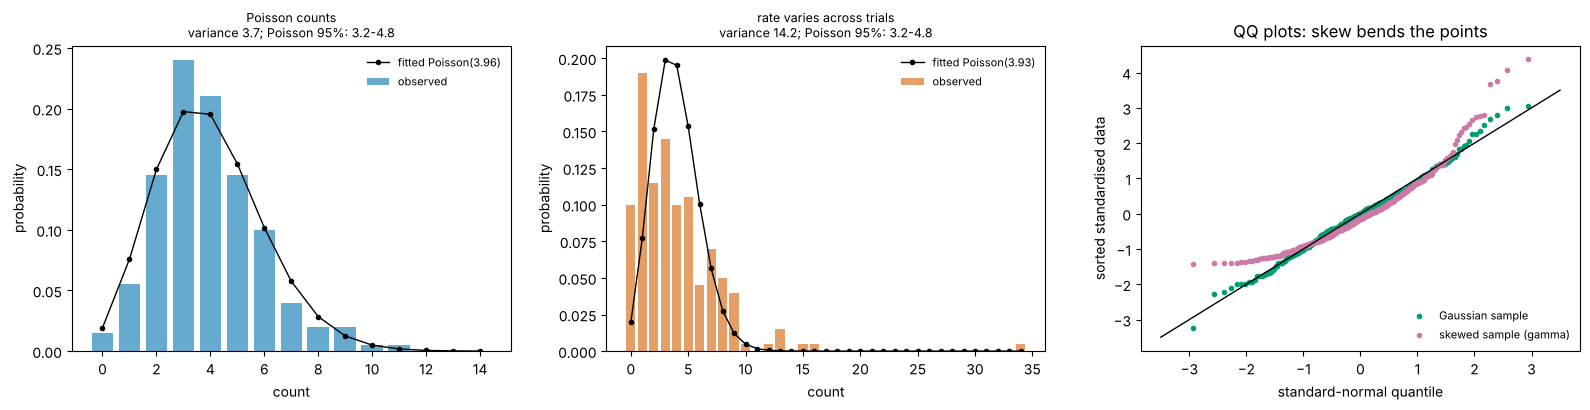

In [11]:
def poisson_check(counts, n_sim=2000, rng=RNG):
    # Fit a Poisson by maximum likelihood and compare variance and P(0) with simulations of the fitted model.
    counts = np.asarray(counts); m = counts.size; lam_hat = counts.mean()
    sims = rng.poisson(lam_hat, size=(n_sim, m))
    stats_obs = (counts.var(ddof=1), np.mean(counts == 0))
    sim_var, sim_p0 = sims.var(axis=1, ddof=1), np.mean(sims == 0, axis=1)
    return lam_hat, stats_obs, (np.percentile(sim_var, [2.5, 97.5]), np.percentile(sim_p0, [2.5, 97.5])), sims

n_tr = 200
cnt_pois = RNG.poisson(4.0, n_tr)                                           # (200,) truly Poisson
cnt_mix = RNG.poisson(RNG.gamma(2.0, 2.0, n_tr))                            # (200,) Poisson given a rate that varies across trials (mean 4)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, cnt), col in zip(axes[:2], [('Poisson counts', cnt_pois), ('rate varies across trials', cnt_mix)], [PALETTE[0], PALETTE[1]]):
    lam_hat, (v_obs, p0_obs), (v_rng, p0_rng), sims = poisson_check(cnt)
    kmax = int(max(cnt.max(), 14))
    ax.bar(np.arange(kmax + 1), np.bincount(cnt, minlength=kmax + 1) / n_tr, color=col, alpha=0.6, label='observed')
    ax.plot(np.arange(kmax + 1), stats.poisson.pmf(np.arange(kmax + 1), lam_hat), 'ko-', ms=3, lw=1, label=f'fitted Poisson({lam_hat:.2f})')
    ax.set_title(f'{name}\nvariance {v_obs:.1f}; Poisson 95%: {v_rng[0]:.1f}-{v_rng[1]:.1f}', fontsize=9)
    ax.set_xlabel('count'); ax.set_ylabel('probability'); ax.legend(fontsize=8, frameon=False, loc='upper right')
    print(f"{name:<26}: lambda_hat {lam_hat:.2f};  variance {v_obs:.2f} vs 95% of fitted-Poisson simulations in {np.round(v_rng, 2)};  "
          f"P(0) {p0_obs:.3f} vs {np.round(p0_rng, 3)}")
gauss_data = RNG.normal(10, 2, 300); skew_data = RNG.gamma(2, 2, 300)
q_theory = stats.norm.ppf((np.arange(1, 301) - 0.5) / 300)
for d, c, lab in [(gauss_data, PALETTE[2], 'Gaussian sample'), (skew_data, PALETTE[3], 'skewed sample (gamma)')]:
    axes[2].plot(q_theory, np.sort((d - d.mean()) / d.std(ddof=1)), 'o', ms=3, color=c, label=lab)
axes[2].plot([-3.5, 3.5], [-3.5, 3.5], 'k-', lw=1)
axes[2].set_xlabel('standard-normal quantile'); axes[2].set_ylabel('sorted standardised data'); axes[2].set_title('QQ plots: skew bends the points'); axes[2].legend(fontsize=8, frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

The fitted rate is close to 4 in both cases (maximum likelihood finds the mean either way). For truly Poisson counts, the observed variance and the fraction of zeros fall inside the range of fitted-Poisson simulations. For counts whose underlying rate varies across trials, the variance is more than three times what a Poisson allows and there are far too many zeros: the Poisson model is **rejected by its own simulations**, even though its fitted mean is right. A model can get the mean right and still be wrong about variability, which is often what matters (decoding, information, error bars).

# **Part 6: Mini-Lab — Fitting Models to a Mouse's Choices and Its Motor Cortex**

### A. A binomial model of a mouse's choices
**Data.** The Lesson 16 session (Steinmetz et al., 2019; mouse Lederberg): on each trial, gratings of contrast 0–1 on each side; the mouse turned the wheel left, right, or not at all. We model the **choice on trials with a wheel turn**: at each contrast difference $c = c_R - c_L$, the number of right turns among the $n_c$ turn trials is $\operatorname{Binomial}(n_c, p_c)$, with $p_c$ the probability of turning right. The curve $p_c$ against $c$ is the mouse's **psychometric function**.

In [12]:
import os, urllib.request
STEIN_FILE = 'steinmetz_s11_lederberg.npz'
for cand in [STEIN_FILE, os.path.join('..', '..', 'data', STEIN_FILE)]:
    if os.path.exists(cand):
        stein_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/8f9e0431a21d8ac0aa016e3502735f3b8627863a/data/' + STEIN_FILE, STEIN_FILE)
    stein_path = STEIN_FILE
dat = np.load(stein_path)
cl, cr, resp = dat['contrast_left'], dat['contrast_right'], dat['response']      # (340,) each; response +1 left, -1 right, 0 none
diff = np.round(cr - cl, 2)                                                     # (340,) contrast difference, right minus left
turned = resp != 0
levels = np.unique(diff)
n_c = np.array([np.sum(turned & (diff == c)) for c in levels])                  # (9,) turn trials per level
k_c = np.array([np.sum((resp == -1) & (diff == c)) for c in levels])            # (9,) right turns per level
p_hat_c = k_c / n_c
se_c = np.sqrt(p_hat_c * (1 - p_hat_c) / n_c)
print(f"{'c = cR - cL':>12}{'turn trials':>12}{'right turns':>12}{'p_hat':>8}{'SE':>8}")
for c, n, k, p, s in zip(levels, n_c, k_c, p_hat_c, se_c):
    print(f"{c:>+12.2f}{n:>12}{k:>12}{p:>8.3f}{s:>8.3f}")

# Likelihood comparison: one p for all levels (choice ignores the stimulus) against one p per level.
def binom_loglik(k, n, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.sum(np.log(np.array([comb(int(nn), int(kk)) for kk, nn in zip(np.atleast_1d(k), np.atleast_1d(n))], dtype=float)) + k * np.log(p) + (n - k) * np.log(1 - p))
p_pool = k_c.sum() / n_c.sum()
ll_pool, ll_sep = binom_loglik(k_c, n_c, np.full(len(levels), p_pool)), binom_loglik(k_c, n_c, p_hat_c)
print(f"\nlog-likelihood: one p for all levels ({p_pool:.3f}) {ll_pool:.1f};  one p per level {ll_sep:.1f};  difference {ll_sep - ll_pool:.1f} log units")
hard = np.isclose(np.abs(diff), 0.25) & (cl != cr)                         # hardest unequal trials, turn or not
fb = dat['feedback_type']                                                   # +1 rewarded (correct)
k_h, n_h = int(np.sum((fb == 1) & hard)), int(np.sum(hard))
print(f"hardest unequal trials (|c| = 0.25): {k_h} correct of {n_h};  P(at least that many | guessing) = {stats.binom.sf(k_h - 1, n_h, 0.5):.1e}")

 c = cR - cL turn trials right turns   p_hat      SE
       -1.00          21           0   0.000   0.000
       -0.75          20           0   0.000   0.000
       -0.50          37           1   0.027   0.027
       -0.25          24           4   0.167   0.076
       +0.00          76          47   0.618   0.056
       +0.25          24          22   0.917   0.056
       +0.50          28          23   0.821   0.072
       +0.75          24          22   0.917   0.056
       +1.00          22          22   1.000   0.000

log-likelihood: one p for all levels (0.511) -107.5;  one p per level -9.1;  difference 98.4 log units
hardest unequal trials (|c| = 0.25): 42 correct of 49;  P(at least that many | guessing) = 1.8e-07


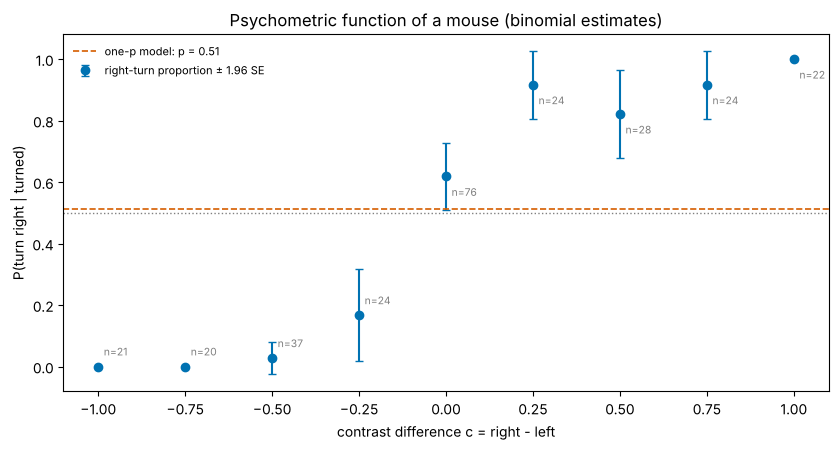

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.errorbar(levels, p_hat_c, yerr=1.96 * se_c, fmt='o', color=PALETTE[0], capsize=3, label='right-turn proportion ± 1.96 SE')
for c, n, p in zip(levels, n_c, p_hat_c):
    ax.annotate(f'n={n}', (c, p), xytext=(4, -14 if p > 0.5 else 8), textcoords='offset points', fontsize=7.5, color='grey')
ax.axhline(p_pool, color=PALETTE[1], ls='--', lw=1.2, label=f'one-p model: p = {p_pool:.2f}')
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xlabel('contrast difference c = right - left'); ax.set_ylabel('P(turn right | turned)'); ax.set_ylim(-0.08, 1.08)
ax.set_title('Psychometric function of a mouse (binomial estimates)'); ax.legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

**Reading the psychometric function.**
- At every non-zero contrast difference the mouse turns towards the higher contrast far more often than chance, with standard errors of a few percentage points; on its hardest unequal trials ($|c| = 0.25$, counting trials without a turn as errors) it is correct 42 times out of 49, which a guessing mouse would match with probability about $2 \times 10^{-7}$.
- At $c = 0$ (equal contrasts, including no grating) it turns right on 62% of 76 turn trials: a bias towards the right, about 2.1 standard errors above 0.5.
- The one-$p$ model, which says the choice ignores the stimulus, is worse by about 98 log-likelihood units: the data are about $e^{98}$ times more probable under the per-level model. (Comparing models with different numbers of parameters fairly needs more care; Lessons 19 and 20 return to it.)
- **Where the binomial SE fails:** at $c = \pm1$ and $c = -0.75$ every choice went one way, so $\hat p$ is 0 or 1 and the formula gives SE = 0. With 20–22 trials that is not certainty; the formula comes from a curvature that is undefined at the boundary. (A Bayesian estimate in Lesson 19 handles this.)

### B. Are motor-cortex spike counts Poisson?
**Data.** A second session of the same experiment (Steinmetz et al., 2019; mouse Hench, data CC0), keeping the 447 neurons in primary motor cortex (MOp): spike counts in 342 trials of 2.5 s, regrouped into fifty 50 ms bins per trial. The file stores `spikes` with shape (342, 447, 250) = (trials, neurons, 10 ms bins); we build `spk` with shape (342, 50, 447) = (trials, 50 ms bins, neurons), and also flatten it to (17100, 447) = (all bins, neurons).

In [14]:
MOP_FILE = 'steinmetz_s10_hench_mop.npz'
for cand in [MOP_FILE, os.path.join('..', '..', 'data', MOP_FILE)]:
    if os.path.exists(cand):
        mop_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/' + MOP_FILE, MOP_FILE)
    mop_path = MOP_FILE
mop = np.load(mop_path)
n_tr, n_neu, _ = mop['spikes'].shape
spk = mop['spikes'].reshape(n_tr, n_neu, 50, 5).sum(axis=3).transpose(0, 2, 1).astype(int)   # (342, 50, 447) spikes per 50 ms bin
spk_flat = spk.reshape(-1, n_neu)                                          # (17100, 447) all bins x neurons
print("counts:", spk.shape, " total recorded time", spk_flat.shape[0] * 0.05, "s")
mu_n = spk_flat.mean(axis=0)
top = np.argsort(-mu_n)[:4]                                                # the four highest-rate neurons
print(f"{'neuron':>7}{'rate (/s)':>10}{'mean':>7}{'var':>7}{'Fano':>6}{'P(0) observed':>15}{'P(0) Poisson':>14}{'P(>=8) obs':>12}{'P(>=8) Pois':>13}")
for j in top:
    c = spk_flat[:, j]; lam_hat = c.mean()
    print(f"{j:>7}{lam_hat / 0.05:>10.1f}{lam_hat:>7.2f}{c.var(ddof=1):>7.2f}{c.var(ddof=1) / lam_hat:>6.2f}"
          f"{np.mean(c == 0):>15.4f}{stats.poisson.pmf(0, lam_hat):>14.4f}{np.mean(c >= 8):>12.4f}{stats.poisson.sf(7, lam_hat):>13.4f}")

counts: (342, 50, 447)  total recorded time 855.0 s
 neuron rate (/s)   mean    var  Fano  P(0) observed  P(0) Poisson  P(>=8) obs  P(>=8) Pois
    434      67.8   3.39   9.76  2.88         0.2398        0.0337      0.1226       0.0228
    433      37.2   1.86   1.17  0.63         0.0528        0.1555      0.0003       0.0007
    323      34.2   1.71   3.09  1.81         0.2282        0.1811      0.0211       0.0004
    135      33.8   1.69   2.61  1.55         0.3035        0.1846      0.0009       0.0004


neuron 434:   window     mean  mean / window  variance   Fano
             50ms     3.39         67.8/s      9.76   2.88
            100ms     6.78         67.8/s     34.90   5.15
            250ms    16.95         67.8/s    193.82  11.43
            500ms    33.91         67.8/s    699.54  20.63
           1250ms    84.77         67.8/s   2791.20  32.92
           2500ms   169.55         67.8/s   5935.90  35.01


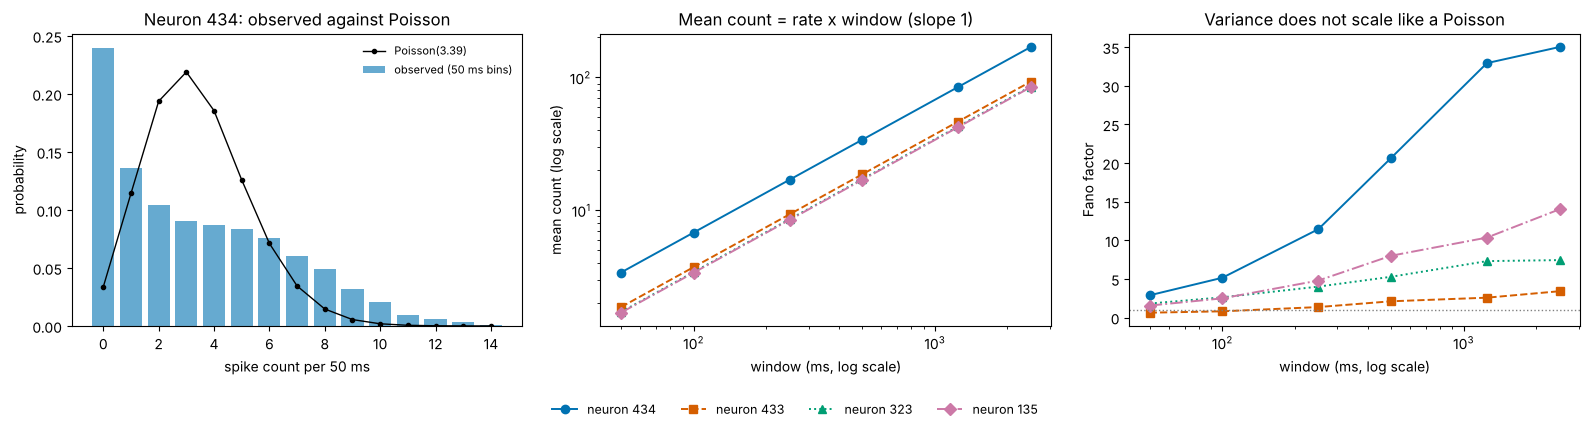

Fano factors at 50 ms and 2.5 s: {434: (2.88, 35.01), 433: (0.63, 3.4), 323: (1.81, 7.43), 135: (1.55, 14.01)}

simulation check on the first 2000 bins of neuron 434: variance 10.17 vs fitted-Poisson 95% range [3.18 3.65]


In [15]:
j0 = top[0]
c0 = spk_flat[:, j0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
kk = np.arange(0, 15)
axes[0].bar(kk, np.bincount(c0, minlength=15)[:15] / c0.size, color=PALETTE[0], alpha=0.6, label='observed (50 ms bins)')
axes[0].plot(kk, stats.poisson.pmf(kk, c0.mean()), 'ko-', ms=3, lw=1, label=f'Poisson({c0.mean():.2f})')
axes[0].set_xlabel('spike count per 50 ms'); axes[0].set_ylabel('probability'); axes[0].set_title(f'Neuron {j0}: observed against Poisson'); axes[0].legend(fontsize=8, frameon=False, loc='upper right')

agg_bins = np.array([1, 2, 5, 10, 25, 50])                                 # windows of 50 ms to 2.5 s, always within one trial
print(f"neuron {j0}: {'window':>8}{'mean':>9}{'mean / window':>15}{'variance':>10}{'Fano':>7}")
fano_tab = {}
for i, j in enumerate(top):
    ffs, means = [], []
    for a in agg_bins:
        cw = spk[:, :, j].reshape(n_tr, 50 // a, a).sum(axis=2).ravel()  # counts in windows of a x 50 ms within trials
        means.append(cw.mean()); ffs.append(cw.var(ddof=1) / cw.mean())
        if j == j0:
            print(f"{'':>8}{a * 50:>7}ms{cw.mean():>9.2f}{cw.mean() / (a * 0.05):>13.1f}/s{cw.var(ddof=1):>10.2f}{ffs[-1]:>7.2f}")
    fano_tab[j] = ffs
    axes[1].loglog(agg_bins * 50, means, marker=MARKERS[i], color=PALETTE[i], ls=LINESTYLES[i], lw=1.4, label=f'neuron {j}')
    axes[2].semilogx(agg_bins * 50, ffs, marker=MARKERS[i], color=PALETTE[i], ls=LINESTYLES[i], lw=1.4, label=f'neuron {j}')
axes[1].set_xlabel('window (ms, log scale)'); axes[1].set_ylabel('mean count (log scale)'); axes[1].set_title('Mean count = rate x window (slope 1)')
axes[2].axhline(1, color='grey', ls=':', lw=1)
axes[2].set_xlabel('window (ms, log scale)'); axes[2].set_ylabel('Fano factor'); axes[2].set_title('Variance does not scale like a Poisson')
fig.legend(*axes[2].get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.show()
print("Fano factors at 50 ms and 2.5 s:", {int(j): (round(float(f[0]), 2), round(float(f[-1]), 2)) for j, f in fano_tab.items()})

lam_hat, (v_obs, p0_obs), (v_rng, p0_rng), _ = poisson_check(c0[:2000], n_sim=1000)
print(f"\nsimulation check on the first 2000 bins of neuron {j0}: variance {v_obs:.2f} vs fitted-Poisson 95% range {np.round(v_rng, 2)}")

**Reading the motor-cortex counts.**
- **Interval scaling of the mean holds exactly**: the mean count per second is the same for every window, a property of counting, not of the Poisson model.
- **The Poisson model fails, and mostly by being too narrow.** Three of the four highest-rate neurons are **over**-dispersed already in 50 ms bins (Fano factors 1.6–2.9). Neuron 434 is the extreme case: it has far more empty bins (24% against 3% for a Poisson with its mean) *and* far more very full ones (12% of bins with 8 or more spikes, against 2%). Its rate is not constant: it is nearly silent while the wheel is still and fires fast while it turns (Lessons 8 and 11), so its counts are a **mixture** of a low-rate and a high-rate Poisson-like process, which is wider than either. Neuron 433 is the exception: **under**-dispersed at 50 ms (Fano 0.63), the regular firing that refractoriness produces.
- **At long windows the Fano factor grows enormously** (to 35 for neuron 434 over a 2.5 s trial, and above 1 for all four), because over a long window the count depends on how much the mouse moved, which a constant-rate Poisson model does not include. The Poisson model is wrong at short windows for one reason (rate switching, or refractoriness) and at long windows for another (behaviour).
- **A simulation check is decisive** even with 2,000 bins: the observed variance (about 10) lies far outside the range that the fitted Poisson produces (about 3.2–3.7).

### C. When sums become Gaussian, and when they do not

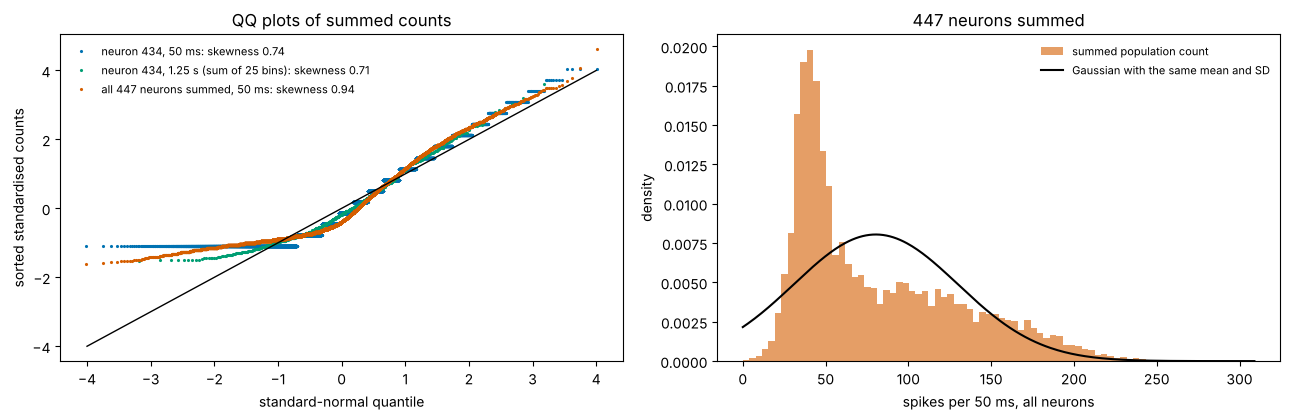

population count: mean 80.4, SD 49.6;  sum of individual variances 129 vs population variance 2457


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for a, c, lab in [(1, PALETTE[0], '50 ms'), (25, PALETTE[2], '1.25 s (sum of 25 bins)')]:
    cw = spk[:, :, j0].reshape(n_tr, 50 // a, a).sum(axis=2).ravel()
    zs = np.sort((cw - cw.mean()) / cw.std(ddof=1))
    axes[0].plot(stats.norm.ppf((np.arange(1, zs.size + 1) - 0.5) / zs.size), zs, '.', ms=2.5, color=c, label=f'neuron {j0}, {lab}: skewness {stats.skew(cw):.2f}')
pop = spk_flat.sum(axis=1)                                                 # (17100,) summed count of all 447 neurons per 50 ms
zp = np.sort((pop - pop.mean()) / pop.std(ddof=1))
axes[0].plot(stats.norm.ppf((np.arange(1, zp.size + 1) - 0.5) / zp.size), zp, '.', ms=2.5, color=PALETTE[1], label=f'all {n_neu} neurons summed, 50 ms: skewness {stats.skew(pop):.2f}')
axes[0].plot([-4, 4], [-4, 4], 'k-', lw=1)
axes[0].set_xlabel('standard-normal quantile'); axes[0].set_ylabel('sorted standardised counts'); axes[0].set_title('QQ plots of summed counts'); axes[0].legend(fontsize=8, frameon=False)
axes[1].hist(pop, bins=80, density=True, color=PALETTE[1], alpha=0.6, label='summed population count')
xx = np.linspace(pop.min(), pop.max(), 300)
axes[1].plot(xx, stats.norm.pdf(xx, pop.mean(), pop.std(ddof=1)), 'k-', lw=1.5, label='Gaussian with the same mean and SD')
axes[1].set_xlabel('spikes per 50 ms, all neurons'); axes[1].set_ylabel('density'); axes[1].set_title(f'{n_neu} neurons summed'); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
print(f"population count: mean {pop.mean():.1f}, SD {pop.std(ddof=1):.1f};  sum of individual variances {spk_flat.var(axis=0, ddof=1).sum():.0f} vs population variance {pop.var(ddof=1):.0f}")

Neither kind of sum becomes Gaussian here. Summing one neuron's counts over twenty-five 50 ms bins (1.25 s) leaves the skewness almost unchanged (0.74 to 0.71): the 25 terms are not independent draws from one distribution, because within a trial the neuron is either mostly at rest or mostly moving. Summing **all 447 neurons** in each 50 ms bin gives a population count that is **bimodal**, a peak near 40 spikes per bin when the wheel is still and a broad shoulder up to 250 when it turns, and nothing like a Gaussian. The CLT's assumption of independent terms fails badly: the population variance (about 2,460) is 19 times the sum of the individual variances (about 130), because the neurons rise and fall together with the movement. The "447 terms" behave like a few large common terms. Large $n$ alone does not guarantee a Gaussian.

**Limitations.** Choice model: trials pooled across the session (engagement changes), only turn trials, and $p_c$ estimated separately at each level rather than with a smooth psychometric curve. Count model: high-rate neurons only, one session, and the movement ignored; a model whose rate depends on wheel speed (the Poisson model of Lesson 12) would be the natural next step.

# **Part 7: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Bernoulli / binomial | choices and correct trials; psychometric functions; quantal synaptic release | binary classification; accuracy of a classifier on $n$ test examples; logistic regression's likelihood |
| Poisson | spike counts; miniature synaptic events; photon counts in imaging; the reference for Fano factors | count regression; Poisson GLMs (Lesson 12's model); event data |
| Interval scaling | rate × window; comparing counts across window lengths | rate models for event streams |
| Gaussian, standardisation | membrane-potential noise; measurement error; z-scored responses | Gaussian noise in least squares (Lesson 5's MSE is a Gaussian log-likelihood); weight initialisation |
| Central limit theorem | sums of synaptic inputs; trial averages; why error bars use $\pm 1.96\,\mathrm{SE}$ | mini-batch gradient noise; averaging metrics |
| Maximum likelihood | fitting tuning curves, GLMs, psychometric functions | cross-entropy loss = negative Bernoulli log-likelihood; MSE = Gaussian |
| Goodness-of-fit by simulation | checking Poisson assumptions; over- and under-dispersion | posterior predictive and calibration checks |

# **Part 8: Summary, Exit Ticket and Lesson 19 Preview**

| Model | PMF / PDF | Mean | Variance | Arises from |
|---|---|---|---|---|
| Bernoulli($p$) | $P(1) = p$ | $p$ | $p(1 - p)$ | one yes/no trial |
| Binomial($n, p$) | $\binom nk p^k(1-p)^{n-k}$ | $np$ | $np(1 - p)$ | $n$ independent trials, same $p$ |
| Poisson($\lambda$) | $\lambda^k e^{-\lambda}/k!$ | $\lambda$ | $\lambda$ | many rare independent chances; $\lambda = r w$ |
| Gaussian($\mu, \sigma^2$) | $\frac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/2\sigma^2}$ | $\mu$ | $\sigma^2$ | sums of many independent terms (CLT) |

| Step | Tool | What to remember |
|---|---|---|
| Estimate | maximum likelihood: maximise $\ell(\theta) = \sum_i \log P(x_i \mid \theta)$ | binomial $k/n$; Poisson $\bar x$; Gaussian $\bar x$ and $\hat\sigma^2$ (divisor $n$) |
| Precision | $\operatorname{SE} \approx 1/\sqrt{-\ell''(\hat\theta)}$ | $\sqrt{\hat p(1-\hat p)/n}$; $\sqrt{\hat\lambda/m}$; fails at boundaries |
| Check | compare with simulations of the fitted model | the mean can fit while the variance fails |

**Exit ticket.** A neuron's spike counts in 100 ms windows have mean 3.0 and variance 1.2 over 500 trials. A colleague fits a Poisson model "because spike counts are Poisson". What do you tell them, and what would you check next?

*(Suggested answer: the Fano factor is 0.4, far below 1; with 500 trials the variance of a Poisson(3) sample would almost never be as low as 1.2 (simulate to confirm), so the Poisson model is rejected. The counts are more regular than Poisson, typically from refractoriness or regular firing. Check the Fano factor at several window lengths, the interval distribution and its CV, and consider a model with spike-history dependence or a different count distribution. A Poisson fit would get the mean right but overstate the variability, which would distort error bars and decoding.)*

**Lesson 19 — Bayesian inference and decisions.** The likelihood tells us how probable the data are for each parameter value, but not how probable each parameter value is given the data. Bayes' rule does that, by combining the likelihood with a prior. It also handles the boundary cases where $\hat p = 0$ or 1, and leads to decisions that weigh evidence against costs.

**Further reading.** J. K. Blitzstein and J. Hwang, *Introduction to Probability*, 2nd ed. (2019), Chapters 3–5 and 10; P. Dayan and L. F. Abbott, *Theoretical Neuroscience* (2001), Chapter 1; N. A. Steinmetz et al., *Nature* 576 (2019); J. del Castillo and B. Katz, "Quantal components of the end-plate potential", *Journal of Physiology* 124 (1954).